# Vendor Payment Guard

Agentic AI (STAI343) midterm project: a LangGraph agent that checks vendor invoices before they get paid.

Invoice fraud usually works like this. Someone gets into a supplier's email, or fakes it, and sends a normal-looking invoice
where the bank account has been swapped for their own. The PO number and amount are real, so the accounts team pays it.
Two recent cases in India cost companies ₹2 crore (Chennai) and ₹2.35 crore (Pune).

The agent runs each invoice through a few checks against the company's own records and adds up a risk score.
Low scores are approved and high scores are blocked. Anything in between triggers a phone call to the vendor, on the number
we already have on file, and the agent keeps trying for up to three calls. Incomplete invoices are rejected before any checks run.

Everything runs locally. Decisions come from fixed rules; a local LLM (through Ollama) only helps read invoices that
aren't in our standard format.

## 1. Settings

These are the rules the agent follows. Each warning flag adds points to the risk score, and the score decides the route.
`MAX_CALLS` and `RUN_CONFIG` are what stop the retry loop from running forever (section 10).

In [1]:
USE_LLM   = True                  # let the local LLM read invoices the parser can't
LLM_MODEL = "qwen3:4b-instruct"

MAX_CALLS  = 3                         # phone the vendor at most 3 times
RUN_CONFIG = {"recursion_limit": 20}   # LangGraph stops any run that goes past 20 steps

RISK_POINTS = {
    "DUPLICATE_INVOICE":    100,
    "BANK_DETAILS_CHANGED":  50,
    "NO_MATCHING_PO":        40,
    "INVALID_GSTIN":         40,
    "GSTIN_MISMATCH":        40,
    "AMOUNT_EXCEEDS_PO":     30,
    "GOODS_NOT_RECEIVED":    30,
}
APPROVE_BELOW = 30   # score 0-29: approve
BLOCK_FROM    = 80   # score 80+: block, anything in between: call the vendor

## 2. Company data and test invoices

The company is a small Pune manufacturer, Shakti Auto Components, with five suppliers. In a real setup this would come
from Tally or SAP; here it's a few dictionaries. `CALLBACK_SCRIPT` fakes the phone calls so every run gives the same answer.

In [2]:
VENDORS = {
    "V001": {"name": "Sharma Steel Traders", "gstin": "27AABCS1234F1Z5", "bank_account": "50100234567", "phone": "+91-90000-10001"},
    "V002": {"name": "Patil Plastics",       "gstin": "27AACCP5678K1Z2", "bank_account": "31200456789", "phone": "+91-90000-10002"},
    "V003": {"name": "Gupta Bearings",       "gstin": "27AADFG9012L1Z8", "bank_account": "00912345678", "phone": "+91-90000-10003"},
    "V004": {"name": "Rao Rubber Works",     "gstin": "29AAEFR3456M1Z1", "bank_account": "20456789012", "phone": "+91-90000-10004"},
    "V005": {"name": "Mehta Packaging",      "gstin": "27AAGFM7890N1Z4", "bank_account": "60011223344", "phone": "+91-90000-10005"},
}
PURCHASE_ORDERS = {
    "PO-1001": {"vendor_id": "V001", "amount": 450000},
    "PO-1002": {"vendor_id": "V002", "amount": 120000},
    "PO-1003": {"vendor_id": "V003", "amount": 275000},
    "PO-1004": {"vendor_id": "V004", "amount": 98000},
    "PO-1005": {"vendor_id": "V005", "amount": 60000},
}
GOODS_RECEIPTS = {"PO-1001": "GRN-5001", "PO-1002": "GRN-5002", "PO-1003": "GRN-5003",
                  "PO-1004": "GRN-5004", "PO-1005": "GRN-5005"}
PAID_INVOICES = {("V001", "SST/2026/0398"), ("V002", "PP/26/117")}

# What each vendor says on call 1, call 2, ...  (anyone not listed never answers)
CALLBACK_SCRIPT = {
    "+91-90000-10002": ["no_answer", "confirmed"],   # Patil picks up the second time
    "+91-90000-10003": ["denied"],                   # Gupta never sent this invoice
    "+91-90000-10004": [],                           # Rao never answers
}

The seven test invoices each take a different route through the graph. Invoices 3, 4 and 5 all have a changed bank
account; the only difference is how the vendor answers the phone.

In [3]:
# Invoice label -> field name. Our standard invoices are just "Label: value" lines.
LABELS = {"Invoice No": "invoice_no", "Vendor": "vendor", "PO Number": "po_number",
          "Amount": "amount", "GSTIN": "gstin", "Bank Account": "bank_account"}
REQUIRED_FIELDS = list(LABELS.values())

def make_invoice(*values):
    # None means that line is missing from the invoice
    lines = [f"{label}: {value}" for label, value in zip(LABELS, values) if value is not None]
    return "TAX INVOICE\n" + "\n".join(lines)

TEST_INVOICES = {
    "1. Clean":                     make_invoice("SST/2026/0412", "Sharma Steel Traders", "PO-1001", 450000, "27AABCS1234F1Z5", "50100234567"),
    "2. Duplicate":                 make_invoice("SST/2026/0398", "Sharma Steel Traders", "PO-1001", 450000, "27AABCS1234F1Z5", "50100234567"),
    "3. New bank, vendor confirms": make_invoice("PP/26/131",     "Patil Plastics",       "PO-1002", 120000, "27AACCP5678K1Z2", "77889900112"),
    "4. New bank, vendor denies":   make_invoice("GB-2026-0077",  "Gupta Bearings",       "PO-1003", 275000, "27AADFG9012L1Z8", "66554433221"),
    "5. New bank, no answer":       make_invoice("RRW/0931",      "Rao Rubber Works",     "PO-1004",  98000, "29AAEFR3456M1Z1", "11223344556"),
    "6. Fake GSTIN, new bank":      make_invoice("MP/2026/552",   "Mehta Packaging",      "PO-1005",  60000, "27AAGFM78901Z4",  "99887766554"),
    "7. Missing fields":            make_invoice("MP/2026/553",   "Mehta Packaging",      None,        None, "27AAGFM7890N1Z4", "60011223344"),
}
EXPECTED = dict(zip(TEST_INVOICES, ["APPROVED", "BLOCKED", "APPROVED", "BLOCKED", "BLOCKED", "BLOCKED", "REJECTED"]))

print(TEST_INVOICES["4. New bank, vendor denies"])

TAX INVOICE
Invoice No: GB-2026-0077
Vendor: Gupta Bearings
PO Number: PO-1003
Amount: 275000
GSTIN: 27AADFG9012L1Z8
Bank Account: 66554433221


## 3. Tools

The nodes don't look anything up themselves; they call these functions. `call_vendor` is simulated and just returns
whatever `CALLBACK_SCRIPT` says for that attempt.

In [4]:
import re

def find_vendor(name):
    for vendor_id, vendor in VENDORS.items():
        if vendor["name"].lower() == name.strip().lower():
            return {"vendor_id": vendor_id, **vendor}
    return None

def find_purchase_order(po_number):
    return PURCHASE_ORDERS.get(po_number)

def find_goods_receipt(po_number):
    return GOODS_RECEIPTS.get(po_number)

def is_already_paid(vendor_id, invoice_no):
    return (vendor_id, invoice_no) in PAID_INVOICES

def is_valid_gstin_format(gstin):
    # 2-digit state code + 10-character PAN + entity number + "Z" + check character
    return re.fullmatch(r"[0-9]{2}[A-Z]{5}[0-9]{4}[A-Z][1-9A-Z]Z[0-9A-Z]", gstin) is not None

def call_vendor(phone, attempt):
    answers = CALLBACK_SCRIPT.get(phone, [])
    return answers[attempt - 1] if attempt <= len(answers) else "no_answer"

## 4. State

The state is the dictionary that gets passed from node to node. A node never returns the whole thing, only the keys it
changed (its delta), and LangGraph merges that into the state.

By default a new value replaces the old one. `risk_flags` and `audit_log` are declared with `operator.add` instead, so new
items get appended. `risk_flags` needs this because the four checks write to it at the same time (section 9 shows what
happens without it). `audit_log` uses it so each node can add a line without wiping out the earlier ones.

In [5]:
import operator
from typing import TypedDict, Annotated

class PaymentState(TypedDict):
    raw_text: str          # the invoice as received
    invoice: dict          # invoice_no, vendor, po_number, amount, gstin, bank_account
    vendor: dict           # our own record of this vendor
    errors: list[str]      # why the invoice can't be checked, if anything

    risk_flags: Annotated[list[str], operator.add]   # appended to, not replaced
    risk_score: int
    call_attempts: int     # loop counter
    vendor_response: str
    decision: str          # APPROVED / BLOCKED / REJECTED
    reason: str

    audit_log: Annotated[list[str], operator.add]    # one line per node

## 5. Nodes

Each node is a plain function: it takes the state and returns a small dict with whatever it changed.

### Reading the invoice

The parser handles our standard format. If it misses fields and `USE_LLM` is on, we ask the local model to read the
text using tool calling. The model is given `submit_invoice_fields` as a tool and replies with the arguments it wants to
call it with; our code then runs the function.

We don't take those values on trust. While testing, the model sometimes copied things wrong (`PO-1001` came back as
`PO-10_001`, and once a bank account had a digit changed), so any value that doesn't appear in the invoice text is dropped.
If Ollama isn't running, the node just keeps the parser's result.

In [6]:
import ollama

def parse_invoice_text(text):
    invoice = {}
    for line in text.splitlines():
        label, _, value = line.partition(":")
        if label.strip() in LABELS and value.strip():
            invoice[LABELS[label.strip()]] = value.strip()
    return invoice

def submit_invoice_fields(invoice_no: str = "", vendor: str = "", po_number: str = "",
                          amount: str = "", gstin: str = "", bank_account: str = "") -> dict:
    '''Submit the fields you read from the invoice. Use an empty string for any field that is not written on the invoice.

    Args:
        invoice_no: the invoice or bill number
        vendor: the supplier company name
        po_number: the purchase order (PO) number
        amount: the total amount payable in rupees
        gstin: the supplier's 15-character GSTIN
        bank_account: the bank account number the supplier wants to be paid into
    '''
    return dict(invoice_no=invoice_no, vendor=vendor, po_number=po_number,
                amount=amount, gstin=gstin, bank_account=bank_account)

LLM_INSTRUCTIONS = (
    "You read vendor invoices for an accounts team. Call the submit_invoice_fields tool exactly once, "
    "copying every value exactly as it is written on the invoice. Never guess or invent a value: "
    "if a field is not written on the invoice, pass an empty string."
)

def ask_llm_to_read(text):
    response = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "system", "content": LLM_INSTRUCTIONS}, {"role": "user", "content": text}],
        tools=[submit_invoice_fields],
        options={"temperature": 0},
    )
    for call in response.message.tool_calls or []:
        if call.function.name == "submit_invoice_fields":
            return submit_invoice_fields(**call.function.arguments)
    return {}

def to_rupees(value):
    # "Rs. 4,50,000/-" -> 450000
    match = re.search(r"\d[\d,]*(\.\d+)?", str(value))
    return int(float(match.group().replace(",", ""))) if match else None

def read_invoice(state):
    text = state["raw_text"]
    invoice, how = parse_invoice_text(text), "parser"
    missing = [field for field in REQUIRED_FIELDS if field not in invoice]
    if missing and USE_LLM:
        try:
            llm_fields = ask_llm_to_read(text)
            for field in missing:
                value = str(llm_fields.get(field, "")).strip()
                if value and value in text:          # keep it only if it's really in the invoice
                    invoice[field] = value
            how = "parser + local LLM"
        except Exception as error:                   # e.g. Ollama isn't running
            how = f"parser only (LLM unavailable: {type(error).__name__})"
    if "amount" in invoice:
        invoice["amount"] = to_rupees(invoice["amount"])
    found = sum(1 for field in REQUIRED_FIELDS if invoice.get(field))
    return {"invoice": invoice, "audit_log": [f"read_invoice [{how}]: found {found} of 6 fields"]}

### Validating

If a field is missing or the vendor isn't in our records there's nothing to check against, so the invoice will be rejected.

In [7]:
def validate(state):
    invoice = state["invoice"]
    errors = [f"missing {field}" for field in REQUIRED_FIELDS if not invoice.get(field)]
    vendor = find_vendor(invoice.get("vendor", ""))
    if invoice.get("vendor") and vendor is None:
        errors.append("vendor not in our master")
    return {"vendor": vendor or {}, "errors": errors, "audit_log": [f"validate: {'; '.join(errors) or 'ok'}"]}

### The four checks

These run in parallel once the invoice is valid. Each one returns a list of flags, which is often empty.

In [8]:
CHECKS = ["check_duplicate", "check_po_match", "check_bank_change", "check_gstin"]

def report(check_name, flags):
    return {"risk_flags": flags, "audit_log": [f"{check_name}: {', '.join(flags) or 'clean'}"]}

def check_duplicate(state):
    paid = is_already_paid(state["vendor"]["vendor_id"], state["invoice"]["invoice_no"])
    return report("check_duplicate", ["DUPLICATE_INVOICE"] if paid else [])

def check_po_match(state):
    invoice = state["invoice"]
    po = find_purchase_order(invoice["po_number"])
    if po is None or po["vendor_id"] != state["vendor"]["vendor_id"]:
        return report("check_po_match", ["NO_MATCHING_PO"])
    flags = []
    if invoice["amount"] > po["amount"]:
        flags.append("AMOUNT_EXCEEDS_PO")
    if find_goods_receipt(invoice["po_number"]) is None:
        flags.append("GOODS_NOT_RECEIVED")
    return report("check_po_match", flags)

def check_bank_change(state):
    changed = state["invoice"]["bank_account"] != state["vendor"]["bank_account"]
    return report("check_bank_change", ["BANK_DETAILS_CHANGED"] if changed else [])

def check_gstin(state):
    gstin = state["invoice"]["gstin"]
    if not is_valid_gstin_format(gstin):
        return report("check_gstin", ["INVALID_GSTIN"])
    return report("check_gstin", ["GSTIN_MISMATCH"] if gstin != state["vendor"]["gstin"] else [])

### Scoring, calling the vendor, and the final decision

`risk_scorer` runs once all four checks are done. `callback_vendor` uses the phone number from our records, never one
printed on the invoice, because whoever sent a fake invoice controls everything on it. It also counts the calls, which is
what the retry loop depends on.

In [9]:
def risk_scorer(state):
    flags = state["risk_flags"]
    score = sum(RISK_POINTS[flag] for flag in flags)
    return {"risk_score": score, "audit_log": [f"risk_scorer: {', '.join(flags) or 'no flags'} -> score {score}"]}

def callback_vendor(state):
    attempt = state.get("call_attempts", 0) + 1
    phone = state["vendor"]["phone"]
    answer = call_vendor(phone, attempt)
    return {"call_attempts": attempt, "vendor_response": answer,
            "audit_log": [f"callback_vendor: call #{attempt} to {phone} -> {answer}"]}

def finish(decision, reason):
    return {"decision": decision, "reason": reason, "audit_log": [f"{decision}: {reason}"]}

def approve(state):
    if state.get("vendor_response") == "confirmed":
        return finish("APPROVED", "vendor confirmed the invoice by phone")
    return finish("APPROVED", f"low risk (score {state['risk_score']})")

def block(state):
    if state.get("vendor_response") == "denied":
        return finish("BLOCKED", "vendor says they never sent this invoice - likely FRAUD")
    if state.get("vendor_response") == "no_answer":
        return finish("BLOCKED", f"could not reach vendor after {state['call_attempts']} call(s) - unverified")
    return finish("BLOCKED", f"risk score {state['risk_score']} is too high")

def reject(state):
    return finish("REJECTED", "; ".join(state["errors"]))

## 6. Routing

Routers decide which node runs next. They read the state and return a node name; they don't change anything.
When the invoice is valid, `route_after_validate` returns the whole `CHECKS` list, which is how the four checks end up
running in parallel.

The loop lives in `route_after_call`. If the vendor didn't pick up and we're still under `MAX_CALLS`, it sends the
invoice back to `callback_vendor`.

In [10]:
def route_after_validate(state):
    return "reject" if state["errors"] else CHECKS

def route_by_score(state):
    if state["risk_score"] < APPROVE_BELOW:
        return "approve"
    if state["risk_score"] >= BLOCK_FROM:
        return "block"
    return "callback_vendor"

def route_after_call(state):
    if state["vendor_response"] == "confirmed":
        return "approve"
    if state["vendor_response"] == "no_answer" and state["call_attempts"] < MAX_CALLS:
        return "callback_vendor"      # try again
    return "block"

## 7. Building the graph

`add_node` can take a function directly and uses the function's name as the node name. Passing a list to `add_edge`
(`CHECKS` → `risk_scorer`) makes the scorer wait until all four checks have finished.

In [11]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(PaymentState)
for node in [read_invoice, validate, check_duplicate, check_po_match, check_bank_change, check_gstin,
             risk_scorer, callback_vendor, approve, block, reject]:
    builder.add_node(node)

builder.add_edge(START, "read_invoice")
builder.add_edge("read_invoice", "validate")
builder.add_conditional_edges("validate", route_after_validate, ["reject"] + CHECKS)
builder.add_edge(CHECKS, "risk_scorer")
builder.add_conditional_edges("risk_scorer", route_by_score, ["approve", "callback_vendor", "block"])
builder.add_conditional_edges("callback_vendor", route_after_call, ["approve", "callback_vendor", "block"])
for node in ["approve", "block", "reject"]:
    builder.add_edge(node, END)

graph = builder.compile()

## 8. Running the test invoices

Each invoice goes through the graph once. The last column checks the decision against `EXPECTED`.

In [12]:
import pandas as pd

rows = []
for name, text in TEST_INVOICES.items():
    result = graph.invoke({"raw_text": text}, config=RUN_CONFIG)
    rows.append({"invoice": name,
                 "flags": ", ".join(result.get("risk_flags", [])) or "-",
                 "score": result.get("risk_score", "-"),
                 "calls": result.get("call_attempts", 0),
                 "decision": result["decision"],
                 "reason": result["reason"],
                 "as expected": result["decision"] == EXPECTED[name]})
pd.DataFrame(rows)

,invoice,flags,score,calls,decision,reason,as expected
0,1. Clean,-,0,0,APPROVED,low risk (score 0),True
1,2. Duplicate,DUPLICATE_INVOICE,100,0,BLOCKED,risk score 100 is too high,True
2,"3. New bank, vendor confirms",BANK_DETAILS_CHANGED,50,2,APPROVED,vendor confirmed the invoice by phone,True
3,"4. New bank, vendor denies",BANK_DETAILS_CHANGED,50,1,BLOCKED,vendor says they never sent this invoice - lik...,True
4,"5. New bank, no answer",BANK_DETAILS_CHANGED,50,3,BLOCKED,could not reach vendor after 3 call(s) - unver...,True
5,"6. Fake GSTIN, new bank","BANK_DETAILS_CHANGED, INVALID_GSTIN",90,0,BLOCKED,risk score 90 is too high,True
6,7. Missing fields,-,-,0,REJECTED,missing po_number; missing amount,True


## 9. Why `risk_flags` needs a reducer

To check that the reducer really matters, the same four checks are wired into a small graph whose state has a plain
`risk_flags: list[str]`. All four write that key in the same step and LangGraph has no rule for combining them, so it
raises an error. With `operator.add` it just concatenates the four lists, which is what the main graph does.

In [13]:
class StateWithoutReducer(TypedDict):
    invoice: dict
    vendor: dict
    risk_flags: list[str]                             # no reducer
    audit_log: Annotated[list[str], operator.add]

test = StateGraph(StateWithoutReducer)
for check in CHECKS:
    test.add_node(check, globals()[check])
    test.add_edge(START, check)
    test.add_edge(check, END)

parsed = parse_invoice_text(TEST_INVOICES["6. Fake GSTIN, new bank"])
parsed["amount"] = to_rupees(parsed["amount"])
try:
    test.compile().invoke({"invoice": parsed, "vendor": find_vendor(parsed["vendor"])})
except Exception as error:
    print(type(error).__name__ + ":", str(error).splitlines()[0])

InvalidUpdateError: At key 'risk_flags': Can receive only one value per step. Use an Annotated key to handle multiple values.


## 10. The retry loop

Invoices 3 and 5 both go round the loop. Patil picks up on the second call, so the loop ends by itself. Rao never
answers, and the `MAX_CALLS` check in `route_after_call` stops it after three calls.

In [14]:
for name in ["3. New bank, vendor confirms", "5. New bank, no answer"]:
    result = graph.invoke({"raw_text": TEST_INVOICES[name]}, config=RUN_CONFIG)
    print(name)
    for line in result["audit_log"][-(result["call_attempts"] + 1):]:
        print("   ", line)

3. New bank, vendor confirms
    callback_vendor: call #1 to +91-90000-10002 -> no_answer
    callback_vendor: call #2 to +91-90000-10002 -> confirmed
    APPROVED: vendor confirmed the invoice by phone
5. New bank, no answer
    callback_vendor: call #1 to +91-90000-10004 -> no_answer
    callback_vendor: call #2 to +91-90000-10004 -> no_answer
    callback_vendor: call #3 to +91-90000-10004 -> no_answer
    BLOCKED: could not reach vendor after 3 call(s) - unverified


`MAX_CALLS` is the intended way out. `recursion_limit` is the backup in case a bug ever removes it: LangGraph counts
steps (supersteps) and raises `GraphRecursionError` once a run goes past the limit. A normal run needs at most 8 steps,
so 20 leaves plenty of room.

Here the router has no call counter and Rao never answers. The limit is set to 6 just to keep the output short.

In [15]:
from langgraph.errors import GraphRecursionError

def route_after_call_no_guard(state):
    return "callback_vendor" if state["vendor_response"] == "no_answer" else END

loop_test = StateGraph(PaymentState)
loop_test.add_node(callback_vendor)
loop_test.add_edge(START, "callback_vendor")
loop_test.add_conditional_edges("callback_vendor", route_after_call_no_guard, ["callback_vendor", END])

rao = {"vendor_id": "V004", **VENDORS["V004"]}
try:
    for update in loop_test.compile().stream({"vendor": rao}, stream_mode="updates", config={"recursion_limit": 6}):
        print(update["callback_vendor"]["audit_log"][0])
except GraphRecursionError as error:
    print("GraphRecursionError:", str(error).splitlines()[0])

callback_vendor: call #1 to +91-90000-10004 -> no_answer
callback_vendor: call #2 to +91-90000-10004 -> no_answer
callback_vendor: call #3 to +91-90000-10004 -> no_answer
callback_vendor: call #4 to +91-90000-10004 -> no_answer
callback_vendor: call #5 to +91-90000-10004 -> no_answer
callback_vendor: call #6 to +91-90000-10004 -> no_answer
GraphRecursionError: Recursion limit of 6 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


## 11. Visualising the agent

The pictures are drawn with networkx and matplotlib from `graph.get_graph()`, so they always match the compiled graph.
`trace()` records each node's delta as `graph.stream` reports it, and `path_taken()` turns that into the nodes and edges
to highlight. The four parallel checks count as one stage, so `validate` links to all of them and all of them link to the scorer.

In [16]:
import os
import matplotlib.pyplot as plt
import networkx as nx

POSITIONS = {
    "__start__": (0, 12), "read_invoice": (0, 10.8), "validate": (0, 9.6),
    "check_duplicate": (-5, 8), "check_po_match": (-1.7, 8), "check_bank_change": (1.7, 8), "check_gstin": (5, 8),
    "reject": (8.5, 9), "risk_scorer": (0, 6.4), "callback_vendor": (0, 4.8),
    "approve": (-4.5, 3.2), "block": (4.5, 3.2), "__end__": (0, 1.6),
}
NODE_LABELS = {node: node.strip("_").replace("_", "\n") for node in POSITIONS}
COLOURS = {"APPROVED": "#2e7d32", "BLOCKED": "#c62828", "REJECTED": "#ef6c00"}
EDGES = [(edge.source, edge.target) for edge in graph.get_graph().edges]
LOOP = ("callback_vendor", "callback_vendor")

def trace(invoice_name):
    steps = []
    for update in graph.stream({"raw_text": TEST_INVOICES[invoice_name]}, stream_mode="updates", config=RUN_CONFIG):
        steps += list(update.items())
    return steps

def path_taken(steps):
    stages = [["__start__"]]
    for node, _ in steps:
        if node in CHECKS and stages[-1][0] in CHECKS:
            stages[-1].append(node)
        else:
            stages.append([node])
    stages.append(["__end__"])
    visited = {node for stage in stages for node in stage}
    used = {(a, b) for here, after in zip(stages, stages[1:]) for a in here for b in after if (a, b) in EDGES}
    return visited, used

def draw_agent(ax, visited=None, used=(), colour="#1565c0", title="", size=1500, font=6.5):
    visited = set(POSITIONS) if visited is None else visited
    g = nx.DiGraph([e for e in EDGES if e != LOOP])
    nx.draw_networkx_nodes(g, POSITIONS, ax=ax, node_size=size,
                           node_color=[colour if n in visited else "#e0e0e0" for n in g.nodes])
    for edges, col, width in [([e for e in g.edges if e not in used], "#b0b0b0", 1),
                              ([e for e in g.edges if e in used], colour, 2.5)]:
        nx.draw_networkx_edges(g, POSITIONS, ax=ax, edgelist=edges, edge_color=col, width=width, node_size=size, arrowsize=10)
    for nodes, col in [(visited, "white"), (set(POSITIONS) - visited, "#555555")]:
        nx.draw_networkx_labels(g, POSITIONS, ax=ax, font_size=font, font_color=col,
                                labels={n: NODE_LABELS[n] for n in nodes})
    # the retry loop, drawn by hand so it doesn't overlap the scorer
    loop_col = colour if LOOP in used else "#b0b0b0"
    x, y = POSITIONS["callback_vendor"]
    ax.annotate("", xy=(x + 0.6, y - 0.3), xytext=(x + 0.6, y + 0.3),
                arrowprops=dict(arrowstyle="-|>", color=loop_col, lw=2.5 if LOOP in used else 1.2,
                                connectionstyle="arc3,rad=-1.8"))
    ax.text(x + 1.55, y, "retry\nloop", fontsize=font + 1, color=loop_col, va="center")
    ax.set_xlim(-6.2, 9.6); ax.set_ylim(0.8, 12.8); ax.set_title(title, fontsize=10); ax.axis("off")

os.makedirs("assets", exist_ok=True)

### 11.1 The graph

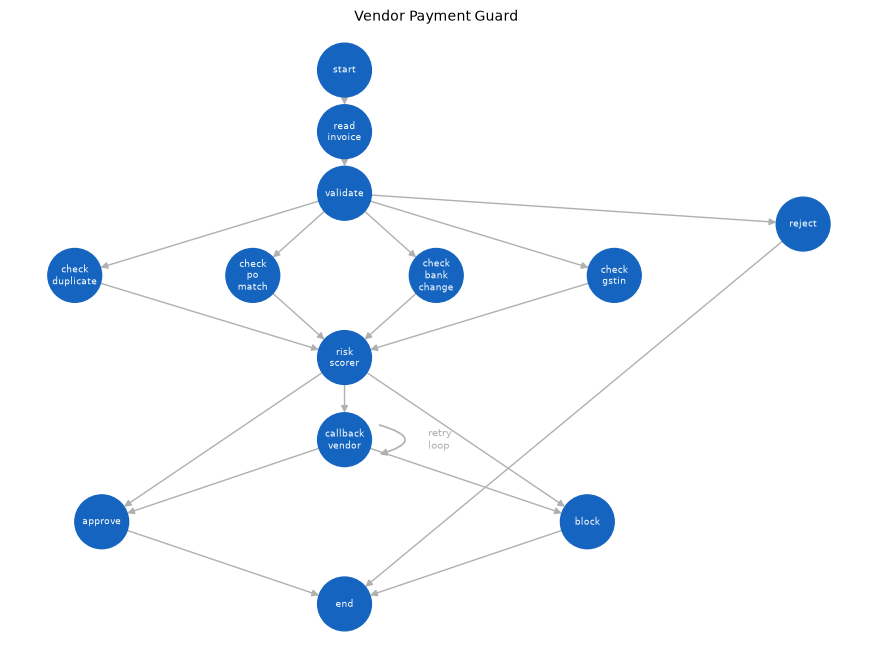

In [17]:
fig, ax = plt.subplots(figsize=(11, 8))
draw_agent(ax, title="Vendor Payment Guard")
fig.savefig("assets/architecture.png", dpi=150, bbox_inches="tight")
plt.show()

### 11.2 The path each invoice took

Green is approved, red is blocked, orange is rejected. Only invoices 3 and 5 use the retry loop, and invoice 7 never
reaches the checks.

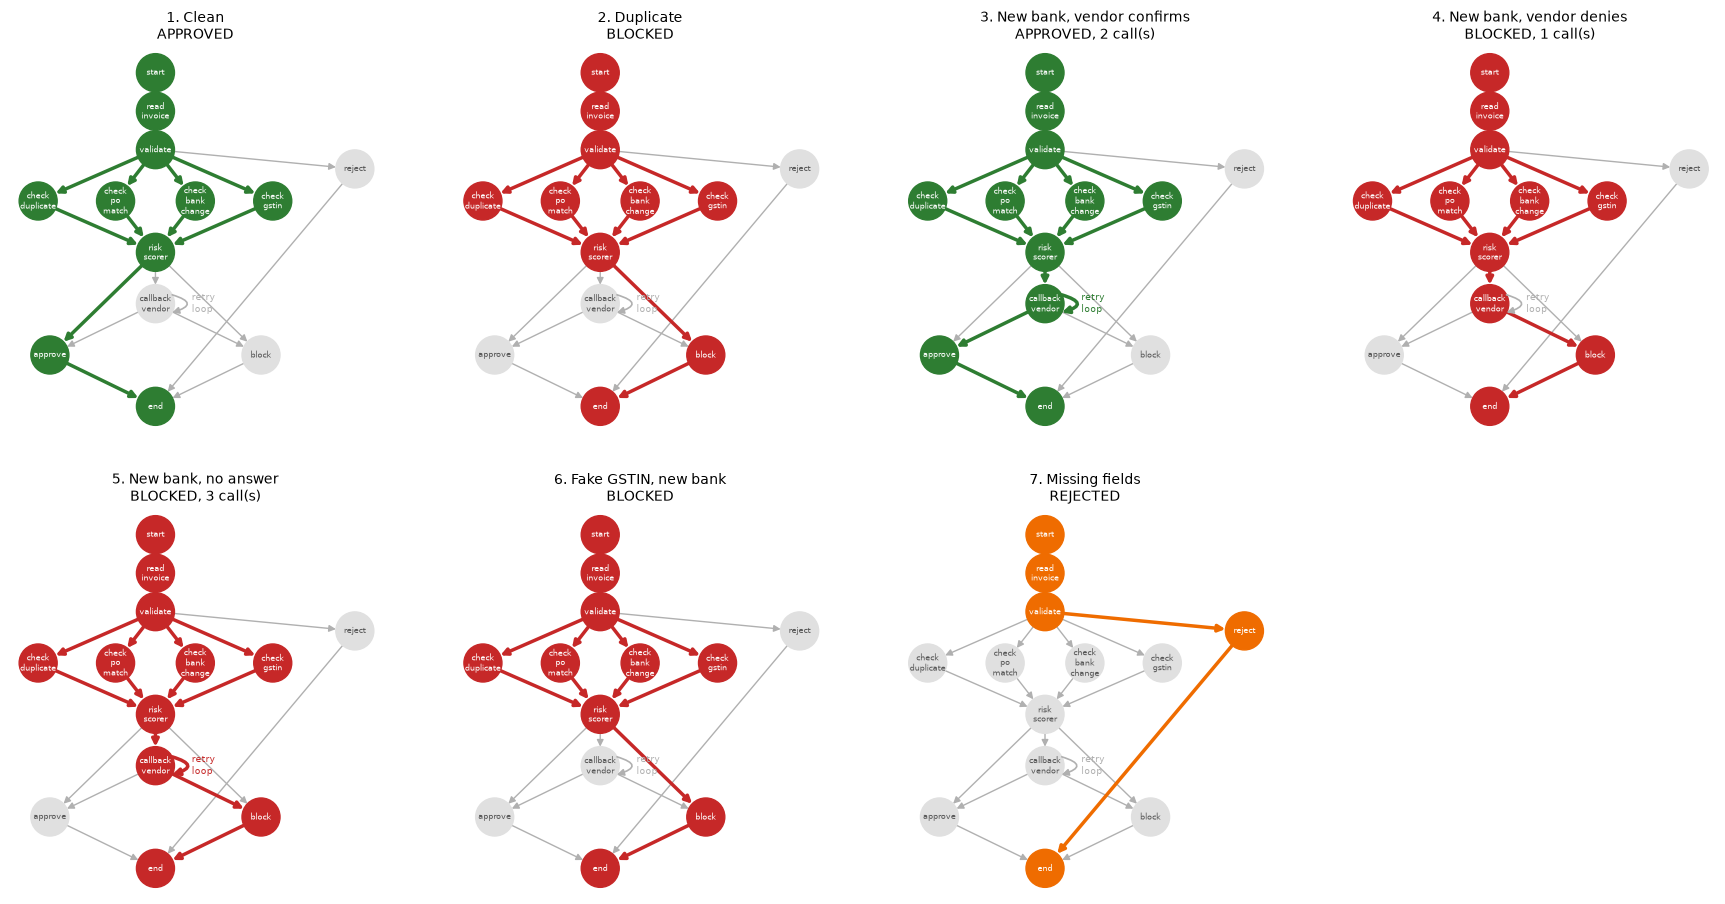

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, name in zip(axes.flat, TEST_INVOICES):
    steps = trace(name)
    decision = steps[-1][1]["decision"]
    calls = sum(node == "callback_vendor" for node, _ in steps)
    draw_agent(ax, *path_taken(steps), COLOURS[decision], f"{name}\n{decision}" + (f", {calls} call(s)" if calls else ""),
               size=750, font=5.5)
axes.flat[-1].axis("off")
fig.savefig("assets/behaviour_paths.png", dpi=120, bbox_inches="tight")
plt.show()

### 11.3 Delta trace for invoice 5

One row per node, showing only what that node returned. Rows 3 to 6 are the parallel checks; by row 7 the scorer sees
their flags merged into one list. Rows 8 to 10 are the loop, with `call_attempts` going up each time.

In [19]:
pd.set_option("display.max_colwidth", 90)

def delta_table(steps):
    return pd.DataFrame([{"node": node, "delta": {k: v for k, v in delta.items() if k != "audit_log"},
                          "audit log": delta["audit_log"][0]} for node, delta in steps],
                        index=range(1, len(steps) + 1))

delta_table(trace("5. New bank, no answer"))

,node,delta,audit log
1,read_invoice,"{'invoice': {'invoice_no': 'RRW/0931', 'vendor': 'Rao Rubber Works', 'po_number': 'PO-...",read_invoice [parser]: found 6 of 6 fields
2,validate,"{'vendor': {'vendor_id': 'V004', 'name': 'Rao Rubber Works', 'gstin': '29AAEFR3456M1Z1...",validate: ok
3,check_bank_change,{'risk_flags': ['BANK_DETAILS_CHANGED']},check_bank_change: BANK_DETAILS_CHANGED
4,check_duplicate,{'risk_flags': []},check_duplicate: clean
5,check_gstin,{'risk_flags': []},check_gstin: clean
6,check_po_match,{'risk_flags': []},check_po_match: clean
7,risk_scorer,{'risk_score': 50},risk_scorer: BANK_DETAILS_CHANGED -> score 50
8,callback_vendor,"{'call_attempts': 1, 'vendor_response': 'no_answer'}",callback_vendor: call #1 to +91-90000-10004 -> no_answer
9,callback_vendor,"{'call_attempts': 2, 'vendor_response': 'no_answer'}",callback_vendor: call #2 to +91-90000-10004 -> no_answer
10,callback_vendor,"{'call_attempts': 3, 'vendor_response': 'no_answer'}",callback_vendor: call #3 to +91-90000-10004 -> no_answer


## 12. Reading a messy invoice with the local LLM

Real invoices often arrive as an email rather than in our template. The parser finds nothing in this one, so without the
LLM it gets rejected. With the LLM on, all six fields come back, each one appears in the text, and the invoice is approved
by the same rules as before.

In [20]:
MESSY_EMAIL = '''Hi Accounts team,
Please find our bill no. SST/2026/0415 for the 12 MS steel coils delivered last week against your order PO-1001.
Total payable: Rs. 4,50,000/- (inclusive of GST). Our GSTIN is 27AABCS1234F1Z5.
Kindly remit the payment to our HDFC current a/c no. 50100234567.
Regards,
Accounts, Sharma Steel Traders'''

for USE_LLM in [False, True]:
    result = graph.invoke({"raw_text": MESSY_EMAIL}, config=RUN_CONFIG)
    print(f"USE_LLM={USE_LLM}: {result['audit_log'][0]} -> {result['decision']} ({result['reason']})")

USE_LLM=False: read_invoice [parser]: found 0 of 6 fields -> REJECTED (missing invoice_no; missing vendor; missing po_number; missing amount; missing gstin; missing bank_account)


USE_LLM=True: read_invoice [parser + local LLM]: found 6 of 6 fields -> APPROVED (low risk (score 0))


For comparison, this is what the model returns for the seven template invoices when it reads them on its own, checked
against the parser. Results vary a little between runs and machines. When the tool description used `PO-1001` as an
example, the model kept returning `PO-10_01` even for the email above, which is part of why only values found in the text
are accepted.

In [21]:
rows = []
for name, text in TEST_INVOICES.items():
    truth, llm = parse_invoice_text(text), ask_llm_to_read(text)
    wrong = [f"{f}: {llm.get(f)!r} (should be {truth.get(f, '')!r})"
             for f in REQUIRED_FIELDS if str(llm.get(f, "")).strip() != truth.get(f, "")]
    rows.append({"invoice": name, "correct": f"{6 - len(wrong)}/6", "mistakes": "; ".join(wrong) or "-"})
pd.DataFrame(rows)

,invoice,correct,mistakes
0,1. Clean,6/6,-
1,2. Duplicate,6/6,-
2,"3. New bank, vendor confirms",5/6,po_number: 'PO-10_02' (should be 'PO-1002')
3,"4. New bank, vendor denies",5/6,po_number: 'PO-1000' (should be 'PO-1003')
4,"5. New bank, no answer",6/6,-
5,"6. Fake GSTIN, new bank",6/6,-
6,7. Missing fields,6/6,-
